In [1]:
# =====================
# 🔧 CONFIGURATION
# =====================
from pathlib import Path

# Path to your data file (CSV or Excel)
DATA_PATH = Path("data/cs_data.xlsx")

# Target column name
TARGET_COL = "Has_Readmission_30_Days"

# Columns you know are categorical (optional). If empty, we'll auto-detect.
CATEGORICAL_COLS = ["Gender", "Primary_Diagnosis", "Has_Hypertension", "Has_Diabetes", 
                    "Has_COPD", "Has_CHF", "Discharge_Status", "Num_Prior_Admissions_Last_6_Months",
                    "Prior_Admission", "Num_Comorbidities"]

# Columns to treat as dates (optional)
DATE_COLS = []

# Optional: columns to drop before modeling
DROP_COLS = ["Patient_ID"]

# Number of CV folds
N_FOLDS = 5

# Random seed for reproducibility
RANDOM_STATE = 42

# Where to write outputs (predictions, metrics, plots)
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {OUTPUT_DIR.resolve()}")

Output directory: /Users/zachrhodes/Code/AEC/src/viz/outputs


In [34]:
# =====================
# 📦 IMPORTS
# =====================
import warnings
warnings.filterwarnings("ignore")

import json
import math
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, precision_score, recall_score,
    mean_squared_error, r2_score, mean_absolute_error, confusion_matrix
)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.utils.multiclass import type_of_target
import matplotlib.pyplot as plt

from sklearn.base import clone

from pygam import LinearGAM, s, f

In [3]:
# =====================
# 📥 LOAD DATA
# =====================
def load_any(DATA_PATH: Path, sheet: str|int|None=None):
    if not DATA_PATH.exists():
        raise FileNotFoundError(f"Data file not found: {DATA_PATH}")
    suf = DATA_PATH.suffix.lower()
    if suf in {".csv"}:
        df = pd.read_csv(DATA_PATH)
    elif suf in {".xlsx", 
                 ".xls"}:
        df = pd.read_excel(DATA_PATH, sheet_name=sheet)
    else:
        raise ValueError(f"Unsupported file type: {suf}")
    return df

df = load_any(DATA_PATH, 
              "Sheet1")
print("Shape:", 
      df.shape)
df.head(3)

Shape: (495, 15)


,Patient_ID,Age,Gender,Primary_Diagnosis,Has_Hypertension,Has_Diabetes,Has_COPD,Has_CHF,Length_of_Stay,Discharge_Status,Num_Prior_Admissions_Last_6_Months,Distance_to_Closest_Hospital,Has_Readmission_30_Days,Prior_Admission,Num_Comorbidities
0,26,81,Female,Respiratory Illness,1,0,0,0,15,Home,1,0.7,0,True,1
1,80,78,Not Specified,Surgery,0,0,0,0,15,Home,0,3.2,0,False,0
2,115,70,Female,Myocardial Infarction,1,0,0,0,15,Other Healthcare Facility,1,2.3,0,True,1


In [20]:
# =====================
# 🧹 BASIC CLEANING & TYPE INFERENCE
# =====================

df.loc[df.Discharge_Status == "Expire"] = "Expired"
df.loc[df.Discharge_Status == "Othr Healthcare Facility"] = "Other Healthcare Facility"

# Drop outliers
df = df.loc[df.Length_of_Stay <= 20]

# Retain only relevant
df = df.loc[df.Discharge_Status != "Expired"]

# Drop ID column
df = df.drop(columns=["Patient_ID"])

# Identify feature matrix and target
y = df[TARGET_COL]
X = df.drop(columns=[TARGET_COL])

# Identify categoricals if not provided
if not CATEGORICAL_COLS:
    # object, category, or low cardinality numerics as categorical heuristic
    cat_guess = []
    for c in X.columns:
        if str(X[c].dtype) in ("object", 
                               "category"):
            cat_guess.append(c)
        else:
            unique = X[c].nunique(dropna=True)
            if unique < 10 and X[c].dtype != "float64" and X[c].dtype != "float32":
                cat_guess.append(c)
    CATEGORICAL_COLS = [c for c in cat_guess if c in X.columns]

NUMERIC_COLS = [c for c in X.columns if c not in CATEGORICAL_COLS]

print("Detected categorical columns:", CATEGORICAL_COLS[:20])
print("Detected numeric columns:", NUMERIC_COLS[:20])

Detected categorical columns: ['Gender', 'Primary_Diagnosis', 'Has_Hypertension', 'Has_Diabetes', 'Has_COPD', 'Has_CHF', 'Discharge_Status', 'Num_Prior_Admissions_Last_6_Months', 'Prior_Admission', 'Num_Comorbidities']
Detected numeric columns: ['Age', 'Length_of_Stay', 'Distance_to_Closest_Hospital']


In [21]:
# =====================
# 🔎 PROBLEM TYPE
# =====================
target_type = type_of_target(y)
if target_type in ("binary", 
                   "multiclass"):
    PROBLEM = "classification"
else:
    # fall back to regression (continuous, or weird)
    PROBLEM = "regression"

print("Problem type:", PROBLEM)

Problem type: classification


In [22]:
# =====================
# 🏗️ PREPROCESSING PIPELINE
# =====================
numeric_pipe = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler(with_mean=False))
])

categorical_pipe = Pipeline(steps=[
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe, NUMERIC_COLS),
        ("cat", categorical_pipe, CATEGORICAL_COLS),
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

In [23]:
# =====================
# ✂️ SPLIT DATA (Holdout for reporting)
# =====================
if PROBLEM == "classification":
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
    )
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE
    )

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (376, 13)  Test shape: (95, 13)


In [24]:
# =====================
# 🤖 MODELS & CV
# =====================
if PROBLEM == "classification":
    base_model_rf = RandomForestClassifier(
        n_estimators=300, max_depth=None, n_jobs=-1, random_state=RANDOM_STATE
    )
else:
    base_model_rf = RandomForestRegressor(
        n_estimators=300, max_depth=None, n_jobs=-1, random_state=RANDOM_STATE
    )

rf_pipe = Pipeline(steps=[("prep", preprocess), ("model", base_model_rf)])

if PROBLEM == "classification":
    cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    scoring = "roc_auc" if y_train.nunique() == 2 else "f1_macro"
else:
    cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    scoring = "neg_root_mean_squared_error"

print("Scoring metric:", scoring)

rf_scores = cross_val_score(rf_pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
print(f"RF {scoring} CV: mean={rf_scores.mean():.4f} ± {rf_scores.std():.4f}")

Scoring metric: roc_auc
RF roc_auc CV: mean=0.8760 ± 0.0278


In [25]:
def _build_terms(n_features: int):
    # Start with the first term, then add—avoids sum() starting at 0
    terms = s(0)
    for i in range(1, n_features):
        terms = terms + s(i)
    return terms

def _to_dense(X):
    # pyGAM expects dense arrays
    return X.toarray() if hasattr(X, "toarray") else np.asarray(X)

gam_scores = None
gam_model = None

In [26]:
# =====================
# 🏆 PICK WINNER(S) & FIT FINAL
# =====================
results = {"scoring": scoring}

def score_name_to_maximization(scoring: str):
    # sklearn convention: metrics starting with "neg_" are minimized in magnitude; we reframe them.
    return -1 if scoring.startswith("neg_") else 1

def summarize_scores(tag, scores):
    if scores is None:
        return None
    return {"mean": float(np.mean(scores)), "std": float(np.std(scores))}

results["rf_cv"]   = summarize_scores("rf", rf_scores)

# Decide which metric value to compare (turn negatives into positives for selection)
def comparable(score_dict, scoring):
    if score_dict is None:
        return None
    if scoring.startswith("neg_"):
        return -score_dict["mean"]
    return score_dict["mean"]

rf_comp   = comparable(results["rf_cv"], scoring)

winners = []
if rf_comp is not None:
    winners.append(("RandomForest", rf_pipe, rf_comp))

winners_sorted = sorted(winners, key=lambda t: t[2], reverse=True)
print("Model leaderboard (by CV metric):")
for name, _, val in winners_sorted:
    print(f"  {name}: {val:.4f}")

# Fit both finalists for reporting (if available)
final_models = {}
if rf_pipe is not None:
    rf_pipe.fit(X_train, y_train)
    final_models["RandomForest"] = rf_pipe

print("Final models ready:", list(final_models.keys()))

with open(OUTPUT_DIR / "cv_results.json", "w") as f:
    json.dump(results, f, indent=2)
print("Saved CV results →", (OUTPUT_DIR / "cv_results.json").resolve())

Model leaderboard (by CV metric):
  RandomForest: 0.8760
Final models ready: ['RandomForest']
Saved CV results → /Users/zachrhodes/Code/AEC/src/viz/outputs/cv_results.json


In [36]:
# =====================
# 🧪 EVALUATE ON HOLDOUT
# =====================
def specificity_macro(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    # For multi-class, cm[i,i] = TP of class i
    # FP = sum of column except TP, FN = sum of row except TP, TN = total - (TP + FP + FN)
    tn_fp_fn_tp = []
    for i in range(len(cm)):
        TP = cm[i, i]
        FP = cm[:, i].sum() - TP
        FN = cm[i, :].sum() - TP
        TN = cm.sum() - (TP + FP + FN)
        spec = TN / (TN + FP) if (TN + FP) > 0 else 0.0
        tn_fp_fn_tp.append(spec)
    return float(np.mean(tn_fp_fn_tp))

def evaluate_classification(y_true, y_pred, y_proba=None):
    out = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "specificity_macro": float(specificity_macro(y_true, y_pred)),
        "recall_macro": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    }
    if y_proba is not None and len(np.unique(y_true)) == 2:
        out["roc_auc"] = float(roc_auc_score(y_true, y_proba[:, 1]))
    return out

def evaluate_regression(y_true, y_pred):
    return {
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "r2": float(r2_score(y_true, y_pred)),
    }

holdout_metrics = {}

for name, model in final_models.items():
    if PROBLEM == "classification":
        # Ensure y_test is encoded if model requires it (MARS)
        y_test_local = y_test

        if hasattr(model, "predict_proba"):
            y_proba = model.predict_proba(X_test)
        else:
            # For MARS acting as regressor, approximate probability by min-max scaling predictions
            preds_raw = model.predict(X_test).reshape(-1, 1)
            min_, max_ = preds_raw.min(), preds_raw.max()
            if max_ == min_:
                probs1 = np.zeros_like(preds_raw).ravel()
            else:
                probs1 = ((preds_raw - min_) / (max_ - min_)).ravel()
            y_proba = np.vstack([1 - probs1, probs1]).T

        y_pred = model.predict(X_test)

        holdout_metrics[name] = evaluate_classification(y_test_local, y_pred, y_proba)

    else:
        y_pred = model.predict(X_test)
        holdout_metrics[name] = evaluate_regression(y_test, y_pred)

print(json.dumps(holdout_metrics, indent=2))

with open(OUTPUT_DIR / "holdout_metrics.json", "w") as f:
    json.dump(holdout_metrics, f, indent=2)
print("Saved holdout metrics →", (OUTPUT_DIR / "holdout_metrics.json").resolve())

{
  "RandomForest": {
    "accuracy": 0.8736842105263158,
    "precision_macro": 0.8207831325301205,
    "specificity_macro": 0.7305194805194806,
    "recall_macro": 0.7305194805194806,
    "f1_macro": 0.7625,
    "roc_auc": 0.9606782106782106
  }
}
Saved holdout metrics → /Users/zachrhodes/Code/AEC/src/viz/outputs/holdout_metrics.json


In [28]:
# =====================
# 💾 SAVE PREDICTIONS
# =====================
for name, model in final_models.items():
    preds = model.predict(X_test)
    out = pd.DataFrame({
        "index": X_test.index,
        "y_true": y_test.values,
        "y_pred": preds
    })
    out.to_csv(OUTPUT_DIR / f"predictions_{name}.csv", index=False)
    print("Saved predictions →", (OUTPUT_DIR / f"predictions_{name}.csv").resolve())

Saved predictions → /Users/zachrhodes/Code/AEC/src/viz/outputs/predictions_RandomForest.csv


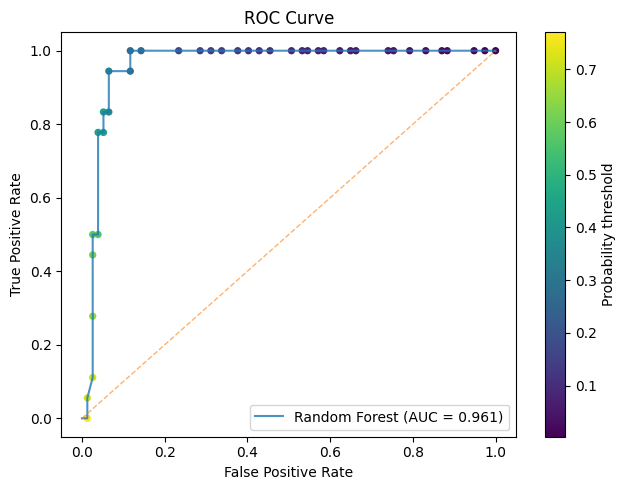

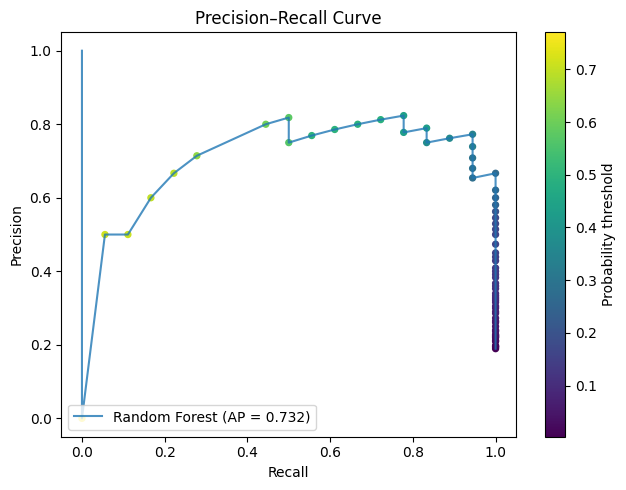

In [29]:
# =====================
# 📈 ROC & PR Curves (with gradient by threshold)
# =====================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, auc, average_precision_score
from sklearn.base import clone

# Reuse if you already defined it above; harmless to redefine.
def _to_dense(X):
    return X.toarray() if hasattr(X, "toarray") else np.asarray(X)

def _get_probs_from_rf(rf_pipe, X):
    """Sklearn Pipeline -> class 1 probabilities"""
    return rf_pipe.predict_proba(X)[:, 1]

def _get_probs_from_gam(gam_pipe, X):
    """Our dict pipeline -> class 1 probabilities"""
    Xtr = _to_dense(gam_pipe["prep"].transform(X))
    return gam_pipe["model"].predict_proba(Xtr)  # shape (n,)

def _ensure_binary01(y):
    """Map arbitrary labels to {0,1} deterministically."""
    y_codes = (pd.Series(y).astype("category").cat.codes).astype(int)
    # In case the 'positive' class isn't the higher code, force 1=positive by keeping as-is
    # (metrics only need consistent 0/1). If you want a specific positive label, map explicitly.
    return y_codes

def _plot_roc_with_grad(ax, y_true, y_prob, label="Model"):
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)

    # drop the first point (threshold=inf) to color by finite thresholds
    fpr_, tpr_, thr_ = fpr[1:], tpr[1:], thr[1:]
    # (optional) clip any residual non-finite just in case
    thr_ = np.asarray(thr_)
    thr_[~np.isfinite(thr_)] = np.nan

    ax.plot(fpr, tpr, lw=1.5, alpha=0.8, label=f"{label} (AUC = {roc_auc:.3f})")
    sc = ax.scatter(fpr_, tpr_, c=thr_, s=18)
    cb = plt.colorbar(sc, ax=ax)
    cb.set_label("Probability threshold")

    ax.plot([0,1], [0,1], linestyle="--", lw=1, alpha=0.6)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title("ROC Curve")
    ax.legend(loc="lower right")


def _plot_pr_with_grad(ax, y_true, y_prob, label="Model"):
    precision, recall, thr = precision_recall_curve(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)

    # thresholds has length == len(precision)-1 == len(recall)-1
    prec_, rec_, thr_ = precision[:-1], recall[:-1], thr
    thr_ = np.asarray(thr_)
    thr_[~np.isfinite(thr_)] = np.nan

    ax.plot(recall, precision, lw=1.5, alpha=0.8, label=f"{label} (AP = {ap:.3f})")
    sc = ax.scatter(rec_, prec_, c=thr_, s=18)
    cb = plt.colorbar(sc, ax=ax)
    cb.set_label("Probability threshold")

    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title("Precision–Recall Curve")
    ax.legend(loc="lower left")


# ---- Compute y_true and probs for both models ----
assert PROBLEM == "classification" and y_test.nunique() == 2, "This plotting block expects binary classification."

y_true = _ensure_binary01(y_test)

# Random Forest probabilities (Pipeline handles its own transform)
rf_probs = _get_probs_from_rf(rf_pipe, X_test)

# pyGAM probabilities (use stored preprocessor inside gam_pipe)
gam_probs = None
if 'gam_pipe' in globals() and gam_pipe is not None:
    gam_probs = _get_probs_from_gam(gam_pipe, X_test)

# ---- Plot ROC side-by-side ----
plt.figure(figsize=(6.5, 5))
ax = plt.gca()
_plot_roc_with_grad(ax, y_true, rf_probs, label="Random Forest")
if gam_probs is not None:
    _plot_roc_with_grad(ax, y_true, gam_probs, label="pyGAM")
plt.tight_layout()
plt.show()

# ---- Plot PR side-by-side ----
plt.figure(figsize=(6.5, 5))
ax = plt.gca()
_plot_pr_with_grad(ax, y_true, rf_probs, label="Random Forest")
if gam_probs is not None:
    _plot_pr_with_grad(ax, y_true, gam_probs, label="pyGAM")
plt.tight_layout()
plt.show()


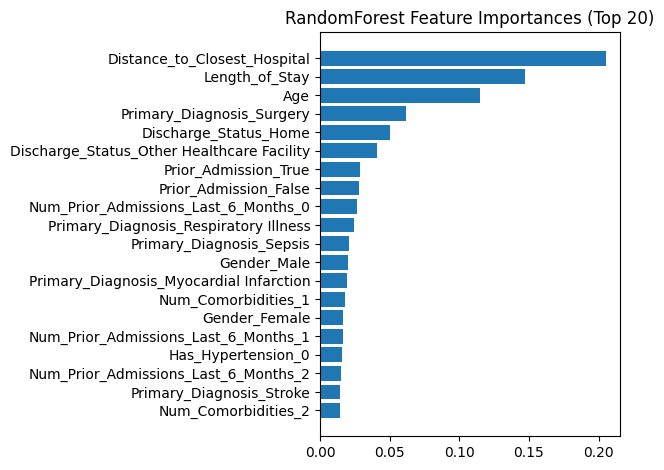

Saved feature importance plot → /Users/zachrhodes/Code/AEC/src/viz/outputs/rf_feature_importance.png


In [30]:
# =====================
# 🌳 FEATURE IMPORTANCE (RF)
# =====================
def get_feature_names(preprocessor, X_sample: pd.DataFrame):
    # Build feature names after ColumnTransformer to align importances
    cat = preprocessor.named_transformers_["cat"]
    num_cols = preprocessor.transformers_[0][2]
    cat_cols = preprocessor.transformers_[1][2]
    # OneHotEncoder feature names
    ohe = cat.named_steps["onehot"]
    cat_expanded = list(ohe.get_feature_names_out(cat_cols))
    return list(num_cols) + cat_expanded

for name, model in final_models.items():
    if "RandomForest" in name:
        # Extract feature importances
        rf = model.named_steps["model"]
        prep = model.named_steps["prep"]
        feat_names = get_feature_names(prep, X_train)
        importances = rf.feature_importances_
        order = np.argsort(importances)[::-1]

        topk = min(20, len(importances))
        plt.figure()
        plt.barh([feat_names[i] for i in order[:topk]][::-1], importances[order[:topk]][::-1])
        plt.title("RandomForest Feature Importances (Top 20)")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "rf_feature_importance.png", dpi=120)
        plt.show()
        print("Saved feature importance plot →", (OUTPUT_DIR / "rf_feature_importance.png").resolve())

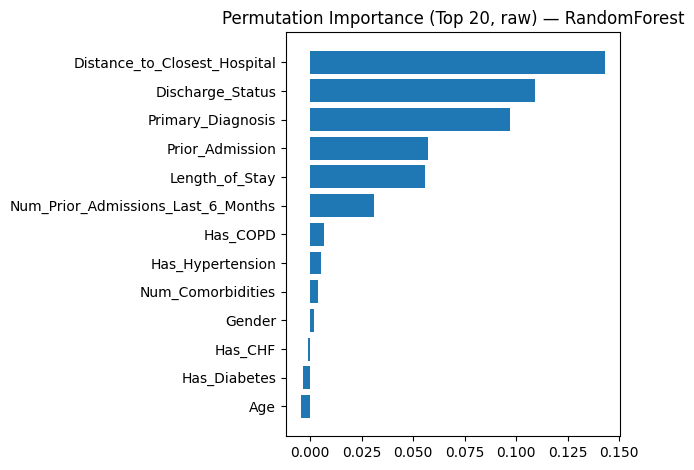

Saved permutation importance plot → /Users/zachrhodes/Code/AEC/src/viz/outputs/perm_importance_raw_RandomForest.png


In [31]:
def compute_permutation_importance_raw(name, pipe, X_df, y_series, n_repeats=5):
    if PROBLEM == "classification":
        scoring_local = "roc_auc" if y_series.nunique() == 2 else "f1_macro"
    else:
        scoring_local = "neg_root_mean_squared_error"

    return permutation_importance(
        pipe, X_df, y_series,
        scoring=scoring_local, n_repeats=n_repeats,
        random_state=RANDOM_STATE, n_jobs=-1
    )

for name, pipe in final_models.items():
    try:
        r = compute_permutation_importance_raw(name, pipe, X_test, y_test)
        feat_names = list(X_test.columns)  # raw columns

        importances = r.importances_mean
        order = np.argsort(importances)[::-1]
        topk = min(20, len(importances))

        plt.figure()
        plt.barh([feat_names[i] for i in order[:topk]][::-1],
                 importances[order[:topk]][::-1])
        plt.title(f"Permutation Importance (Top 20, raw) — {name}")
        plt.tight_layout()
        outpath = OUTPUT_DIR / f"perm_importance_raw_{name}.png"
        plt.savefig(outpath, dpi=120)
        plt.show()
        print("Saved permutation importance plot →", outpath.resolve())
    except Exception as e:
        print(f"Permutation importance failed for {name}: {e}")


<Figure size 640x480 with 0 Axes>

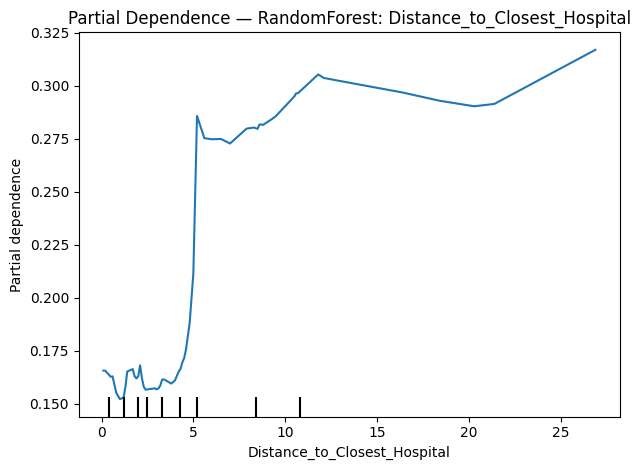

Saved PDP → /Users/zachrhodes/Code/AEC/src/viz/outputs/pdp_RandomForest_Distance_to_Closest_Hospital.png


<Figure size 640x480 with 0 Axes>

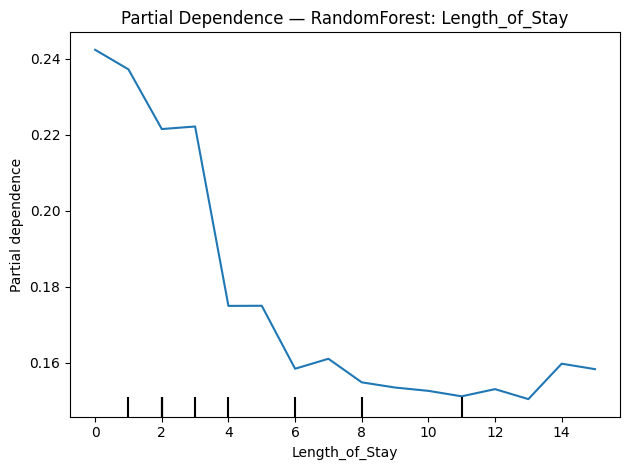

Saved PDP → /Users/zachrhodes/Code/AEC/src/viz/outputs/pdp_RandomForest_Length_of_Stay.png


<Figure size 640x480 with 0 Axes>

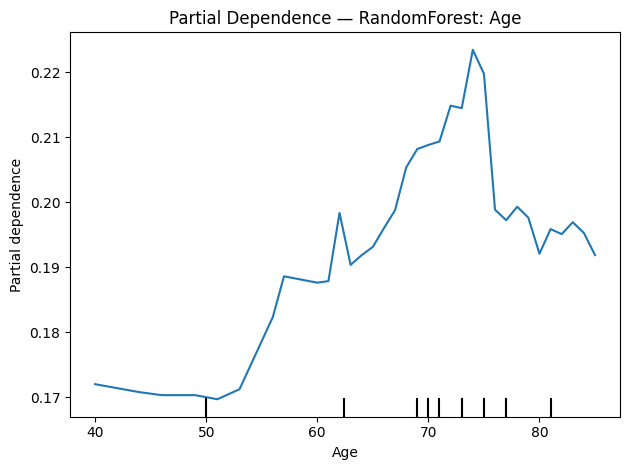

Saved PDP → /Users/zachrhodes/Code/AEC/src/viz/outputs/pdp_RandomForest_Age.png


In [32]:
# =====================
# 📈 PARTIAL DEPENDENCE (Top Numeric Features)
# =====================
def top_numeric_features_by_importance(model, k=3):
    rf = model.named_steps["model"]
    prep = model.named_steps["prep"]
    num_cols = prep.transformers_[0][2]
    if not hasattr(rf, "feature_importances_") or not num_cols:
        return []
    # Map back: feature_importances_ includes both numeric + onehot cats, we only want numeric here.
    # Numeric block is first in our ColumnTransformer, and scaling does not change order.
    n_num = len(num_cols)
    # Take top numeric by importance within the numeric block
    importances = rf.feature_importances_[:n_num]
    order = np.argsort(importances)[::-1]
    return [num_cols[i] for i in order[: min(k, n_num)]]

for name, model in final_models.items():
    if "RandomForest" in name and NUMERIC_COLS:
        top_nums = top_numeric_features_by_importance(model, k=3)
        for feat in top_nums:
            plt.figure()
            try:
                PartialDependenceDisplay.from_estimator(
                    model, X_test, [feat]
                )
                plt.title(f"Partial Dependence — {name}: {feat}")
                plt.tight_layout()
                outpath = OUTPUT_DIR / f"pdp_{name}_{feat}.png"
                plt.savefig(outpath, dpi=120)
                plt.show()
                print("Saved PDP →", outpath.resolve())
            except Exception as e:
                print(f"PDP failed for {name}/{feat}: {e}")